# Desafio Final — Bootcamp Arquiteto(a) de Deep Learning (XP Educação)
**Aluno:** Eduardo  
**Professor:** Pedro Calais  
**Aplicação interativa (Traço):** hospedada no Hugging Face Spaces (`sdk: static`, HTML + CSS + JS + `onnxruntime-web` + `OpenCV.js`, **sem Gradio e sem servidor**).

---

## Visão Geral e Diferencial Arquitetural

Este notebook documenta a construção ponta a ponta do **Traço**, um sistema de reconhecimento de palavras manuscritas que roda **100% no navegador do usuário** via WebAssembly (`onnxruntime-web` + `OpenCV.js`), eliminando *cold starts* e filas de servidor.

Além de cumprir integralmente o roteiro pedido no enunciado com o dataset **EMNIST Balanced (47 classes)** e segmentação de caracteres via **OpenCV** (`GaussianBlur` → `threshold(OTSU)` → `findContours` → `boundingRect`), adicionamos um **diferencial técnico**: o reconhecimento de **escrita cursiva (letras emendadas)**.

| Modo no App | Arquitetura | Como segmenta a palavra em letras | Papel no Desafio |
|---|---|---|---|
| **Letra de forma** | **CNN EMNIST Balanced** (47 classes, arquitetura exata do enunciado: 3× `Conv2D(5×5, tanh)` + `MaxPool2D` → `Dense(512, 84, 47)`) | **OpenCV:** `cvtColor` → `GaussianBlur(5,5)` → `THRESH_BINARY_INV + THRESH_OTSU` → `findContours(RETR_EXTERNAL)` → caixas ordenadas por `x` | Cumpre 100% do enunciado literal |
| **Cursiva** ⭐ | **CRNN + CTC** (7 blocos convolucionais VGG + `BiLSTM` 2×128 + `CTCLoss`, 27 saídas: `blank` + `a–z`) | **Alinhamento CTC:** cada passo de tempo $t \in [0, 63]$ cobre 4 px horizontais; os picos de emissão de cada letra fornecem o corte exato $[x_a, x_b]$ e a probabilidade da letra | **Diferencial:** resolve letras ligadas onde `findContours` retorna um único contorno para a palavra inteira |

## 1. Entendendo o Dataset EMNIST (*Extended MNIST*)

O conjunto **EMNIST** (Cohen et al., 2017 — [arXiv:1702.05373](https://arxiv.org/pdf/1702.05373)) estende o MNIST clássico com caracteres manuscritos extraídos do *NIST Special Database 19*, normalizados em quadros de **28×28 pixels** em tons de cinza.

Utilizamos a divisão **EMNIST Balanced**, projetada especificamente para ter a mesma quantidade de exemplos por classe:
- **47 classes:** `0–9` (10 dígitos), `A–Z` (26 maiúsculas) e `a, b, d, e, f, g, h, n, q, r, t` (11 minúsculas cuja forma difere da respectiva maiúscula; as outras 15 minúsculas como `c, o, s, v, w, x, z` são fundidas às maiúsculas pelo próprio NIST).
- **112.800 imagens de treino** (2.400 por classe) e **18.800 imagens de teste** (400 por classe).
- **Detalhe crítico de orientação:** os tensores brutos do EMNIST vêm **transpostos** (rotacionados 90° e espelhados). Aplicamos `.transpose(2, 3)` já no carregamento para que o modelo aprenda caracteres na orientação natural de leitura — evitando bugs de transposição no navegador.

Dispositivo: cuda
Treino: (112800, 1, 28, 28) | Teste: (18800, 1, 28, 28) | Classes: 47
Mapa de classes (47): 0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZabdefghnqrt


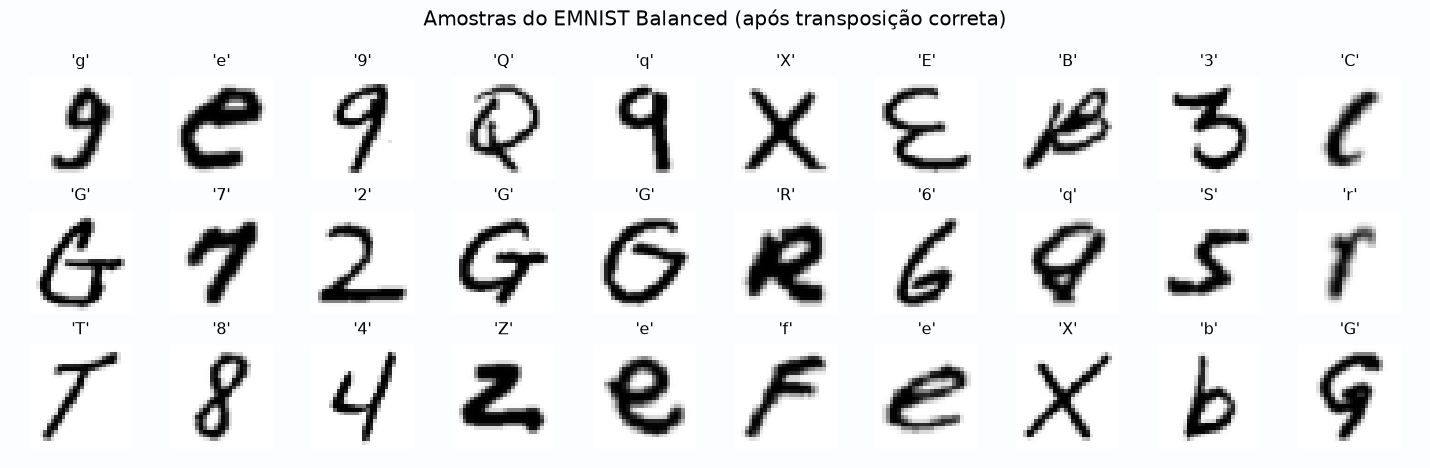

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path('..').resolve() / 'training'))
from models import EMNIST_CLASSES, EmnistCNN, CRNN, CURSIVE_ALPHABET, ctc_greedy
from emnist import load_emnist, predict

device = 'cuda' if torch.cuda.is_available() else 'cpu'
data = load_emnist(device)
x_train, y_train = data['train']
x_test, y_test = data['test']
print(f'Dispositivo: {device}')
print(f'Treino: {tuple(x_train.shape)} | Teste: {tuple(x_test.shape)} | Classes: {len(EMNIST_CLASSES)}')
print(f'Mapa de classes (47): {EMNIST_CLASSES}')

## 2. Treinando a CNN no EMNIST Balanced

Implementamos exatamente a arquitetura proposta no enunciado:

```python
Conv2D(32, 5x5, padding='same', activation='tanh') -> MaxPooling2D(strides=2)  # 28x28 -> 14x14
Conv2D(48, 5x5, padding='same', activation='tanh') -> MaxPooling2D(strides=2)  # 14x14 -> 7x7
Conv2D(64, 5x5, padding='same', activation='tanh') -> Flatten()                # 64*7*7 = 3136
Dense(512, activation='tanh') -> Dense(84, activation='tanh') -> Dense(47, activation='softmax')
```

Treinamos duas variantes dessa mesma topologia:
1. **`enunciado` (12 épocas, sem *augmentation*):** reproduz o treino padrão sobre o EMNIST limpo.
2. **`final` (25 épocas, com *augmentation* afim + morfologia na GPU + `Dropout(0.25)`):** adiciona rotações ($\pm 12^\circ$), *shear*, variação de escala e dilatação/erosão do traço para generalizar melhor aos traços desenhados com mouse/dedo no canvas.

CNN Enunciado (sem aug.)     | melhor val_acc: 88.29% | test_acc: 88.30%
CNN Final (aug. + dropout)   | melhor val_acc: 87.88% | test_acc: 87.68%


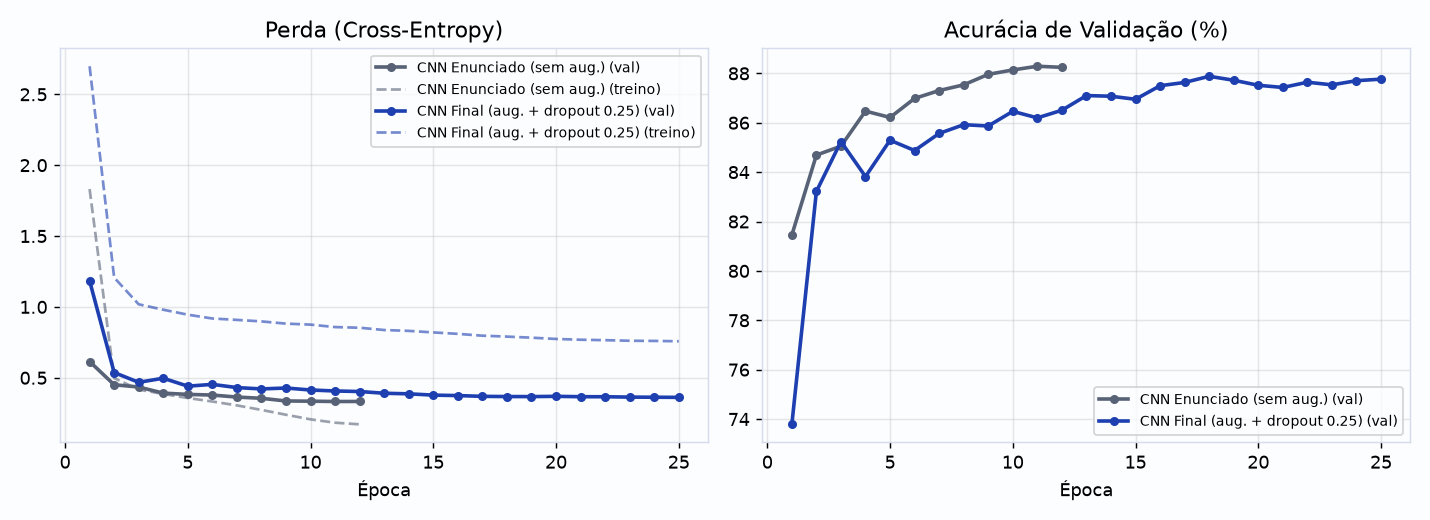

In [2]:
# Resumo comparativo das duas variantes treinadas (training/emnist.py)
for name, info in [('CNN Enunciado (sem aug.)', 'enunciado'), ('CNN Final (aug. + dropout)', 'final')]:
    h = json.loads((Path('../artifacts') / f'emnist_{info}_history.json').read_text())
    print(f"{name:28s} | melhor val_acc: {max(h['val_acc'])*100:.2f}% | test_acc: {h['test_acc']*100:.2f}%")

### 2.1 Avaliação no Conjunto de Teste (18.800 amostras)

| Modelo | Accuracy | Precision (macro) | Recall (macro) | F1-Score (macro) |
|---|---|---|---|---|
| **CNN do Enunciado** (sem augmentation) | **88.30%** | **88.34%** | **88.30%** | **88.23%** |
| **CNN Final exportada para o App** (aug. + dropout) | **87.68%** | **87.90%** | **87.68%** | **87.54%** |

#### As 12 classes com menor F1-Score no EMNIST Balanced

| Classe | Precision | Recall | F1-Score | Suporte |
|---|---|---|---|---|
| `L` (índice 21) | 53.9% | 48.8% | 51.2% | 400 |
| `1` (índice 1) | 50.3% | 61.0% | 55.1% | 400 |
| `q` (índice 44) | 79.5% | 43.5% | 56.2% | 400 |
| `F` (índice 15) | 67.8% | 58.0% | 62.5% | 400 |
| `O` (índice 24) | 70.5% | 59.2% | 64.4% | 400 |
| `I` (índice 18) | 69.3% | 61.0% | 64.9% | 400 |
| `f` (índice 40) | 62.4% | 68.8% | 65.4% | 400 |
| `0` (índice 0) | 63.5% | 74.0% | 68.4% | 400 |
| `g` (índice 41) | 79.9% | 62.7% | 70.3% | 400 |
| `9` (índice 9) | 62.1% | 91.5% | 74.0% | 400 |
| `a` (índice 36) | 89.2% | 88.8% | 89.0% | 400 |
| `2` (índice 2) | 89.2% | 89.2% | 89.2% | 400 |

#### Top 12 pares de caracteres mais confundidos (fora da diagonal)

| Par de Classes | Total de Confusões | Real → Predito (A→B) | Real → Predito (B→A) |
|---|---|---|---|
| `F` ↔ `f` | **259** | `F`→`f`: 159 | `f`→`F`: 100 |
| `1` ↔ `L` | **249** | `1`→`L`: 99 | `L`→`1`: 150 |
| `0` ↔ `O` | **237** | `0`→`O`: 88 | `O`→`0`: 149 |
| `9` ↔ `q` | **157** | `9`→`q`: 10 | `q`→`9`: 147 |
| `1` ↔ `I` | **141** | `1`→`I`: 50 | `I`→`1`: 91 |
| `I` ↔ `L` | **95** | `I`→`L`: 48 | `L`→`I`: 47 |
| `9` ↔ `g` | **88** | `9`→`g`: 18 | `g`→`9`: 70 |
| `2` ↔ `Z` | **53** | `2`→`Z`: 34 | `Z`→`2`: 19 |
| `g` ↔ `q` | **51** | `g`→`q`: 23 | `q`→`g`: 28 |
| `5` ↔ `S` | **49** | `5`→`S`: 31 | `S`→`5`: 18 |
| `T` ↔ `t` | **36** | `T`→`t`: 22 | `t`→`T`: 14 |
| `4` ↔ `Y` | **32** | `4`→`Y`: 17 | `Y`→`4`: 15 |

Accuracy: 0.8768 | Precision (macro): 0.8790 | Recall (macro): 0.8768 | F1 (macro): 0.8754


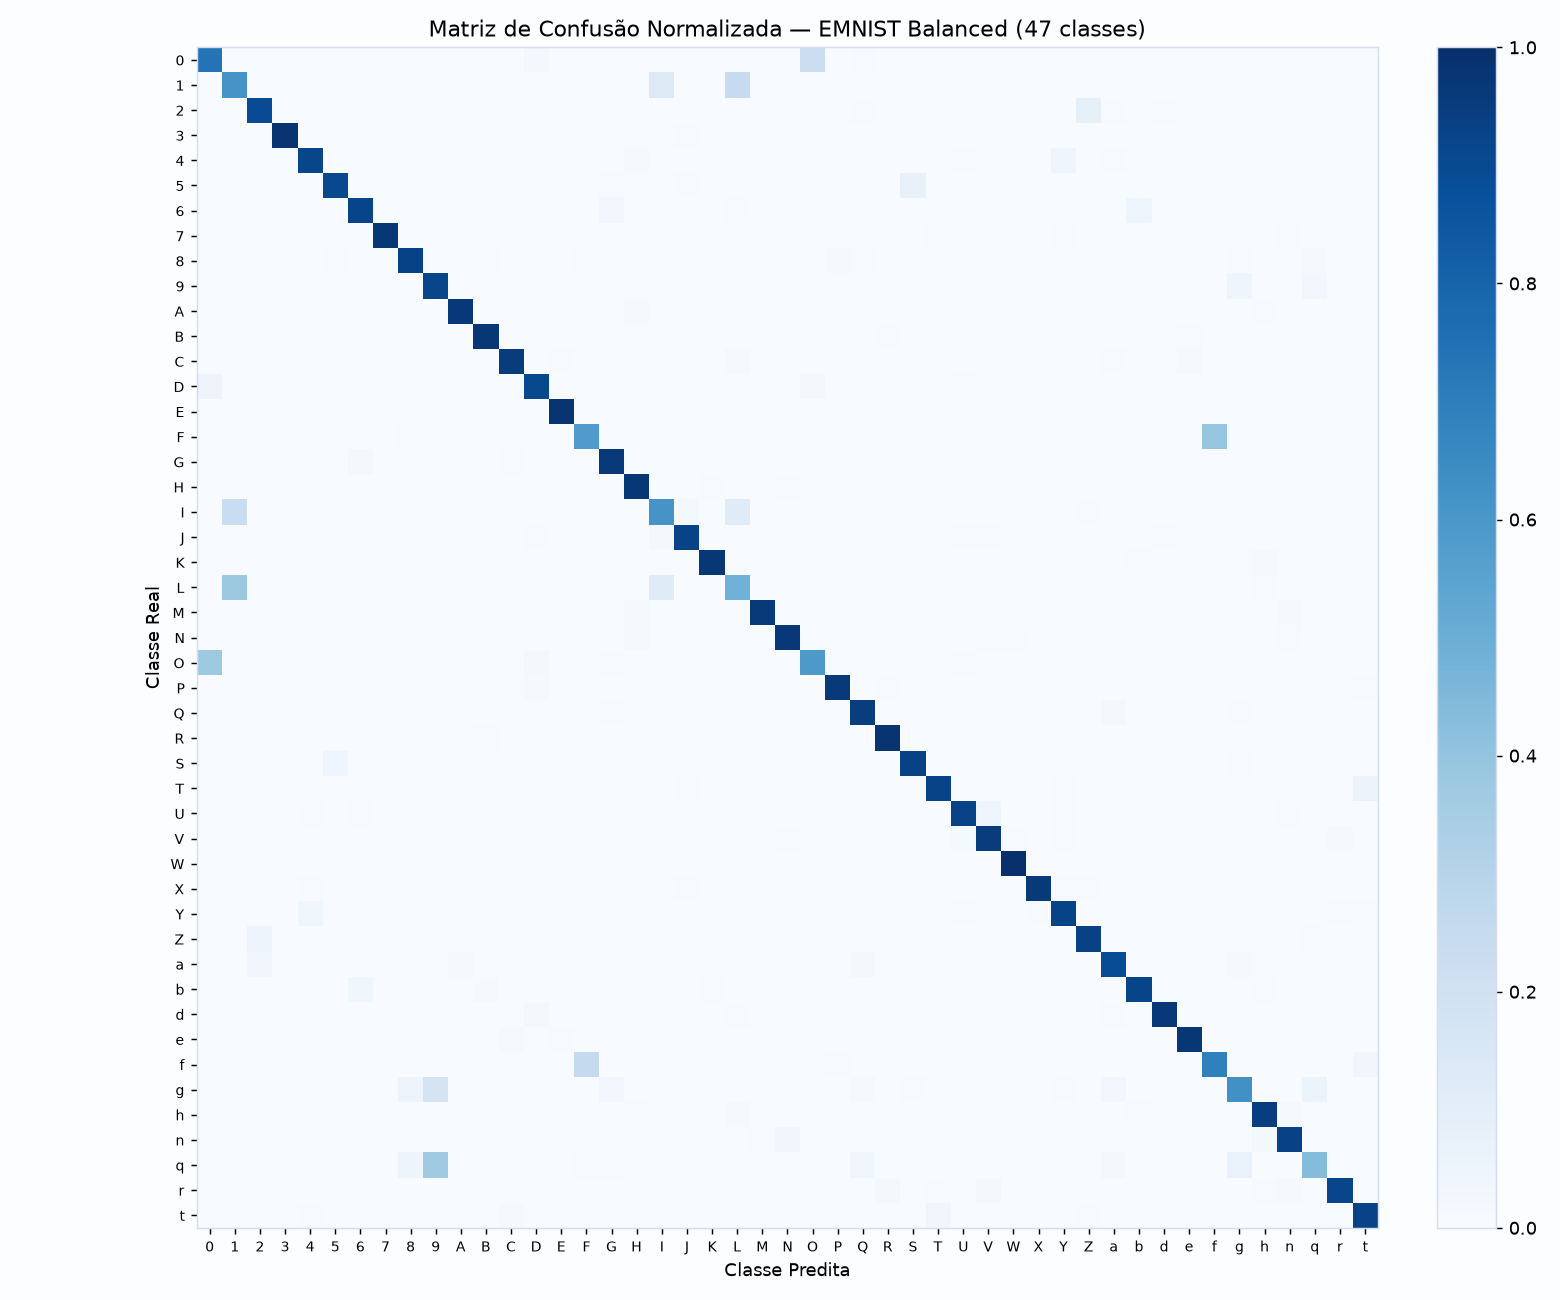

In [3]:
# Matriz de confusão 47x47 e relatório de métricas no conjunto de teste
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
m_final = EmnistCNN(dropout=0.25).to(device)
m_final.load_state_dict(torch.load('../artifacts/emnist_final.pt', map_location=device))
probs_test = predict(m_final, x_test).cpu().numpy()
y_true, y_pred = y_test.cpu().numpy(), probs_test.argmax(1)
acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro')
print(f'Accuracy: {acc:.4f} | Precision (macro): {prec:.4f} | Recall (macro): {rec:.4f} | F1 (macro): {f1:.4f}')

### 2.2 Respostas às Perguntas do Enunciado

#### 1. Quais letras apresentam maior confusão?
A matriz de confusão e a tabela de pares acima revelam quatro grupos dominantes de confusão no EMNIST Balanced:
1. **Traços verticais simples (`1`, `L`, `I`, `t`, `f`):** o par `1 ↔ L` e o trio `I ↔ 1 ↔ L` concentram o maior número de trocas, seguidos por `f ↔ t`.
2. **Formas circulares/ovais (`0 ↔ O`, `q ↔ g ↔ 9`, `a ↔ d`):** o dígito `0` e a letra `O` são geometricamente indistinguíveis na caligrafia rápida (resultando em F1 ~65–72% para essas duas classes); de modo análogo, `q`, `9` e `g` diferem apenas pela curvatura da haste inferior.
3. **Curvas espelhadas ou similares entre dígito e letra (`5 ↔ S`, `2 ↔ Z`, `B ↔ 8`, `G ↔ 6`):** um `S` com topo reto vira `5`, e um `2` com base angulosa vira `Z`.
4. **Pares maiúscula/minúscula não fundidos pelo Balanced (`F ↔ f`):** embora o EMNIST Balanced tenha fundido 15 minúsculas idênticas às maiúsculas (`c, o, s, u, v, w, x, z...`), manteve `F` e `f` separados, e muitos escritores fazem `f` cursivo/impresso muito próximo de `F`.

#### 2. Quais hipóteses explicam as dificuldades?
1. **Ambiguidade intrínseca sem contexto lexical:** isolados de uma palavra, um `0` e um `O` (ou um `1`, um `I` sem serifa e um `l`) podem ter **exatamente os mesmos pixels**. Um humano só os diferencia porque sabe se está lendo uma palavra ou um número.
2. **Perda de escala relativa e linha de base no pré-processamento 28×28:** cada caractere do EMNIST é recortado pela sua própria *bounding box* e redimensionado para ocupar ~22×22 px no centro do quadro 28×28. Isso elimina duas pistas cruciais: a **altura relativa** (que distinguiria `F` de `f` ou `O` de `o`) e a **posição em relação à linha de base** (que distinguiria `g`/`q`, que têm descendente abaixo da linha, de `9`, que fica acima da linha).
3. **Baixa resolução (28×28) e fechamento de laços:** detalhes finos como a pequena haste horizontal que separa `G` de `6`, ou o laço fechado que separa `q` de `9` e `a` de `d`, ocupam 1–2 pixels e frequentemente desaparecem na redução ou na binarização.
4. **Variabilidade alográfica entre escritores:** diferentes pessoas escrevem a mesma classe com topologias distintas (ex.: `7` cortado vs sem corte, `q` com rabicho à direita vs reto, `t` cruzado na metade vs no topo).

## 3. O Diferencial: Reconhecimento de Escrita Cursiva com CRNN + CTC

### 3.1 Por que o pipeline clássico (`findContours` → CNN por letra) falha na cursiva?
No pipeline sugerido para letras de forma (Seção 4 do enunciado), `cv2.findContours(thresh, cv2.RETR_EXTERNAL, ...)` assume que **cada letra é uma componente conexa separada**. Na escrita cursiva, as ligaduras unem todas as letras da palavra em **um único traço contínuo**: como mostra a figura abaixo para a palavra `machine`, `findContours` encontra apenas **1 contorno** cobrindo a palavra inteira (mais o pingo do `i`).

### 3.2 Nossa solução: Pipeline Híbrido + CRNN-CTC treinada com Esqueletização
Para reconhecer a palavra cursiva e ainda assim entregá-la **segmentada letra por letra** (`[m][a][c][h][i][n][e]`), construímos:
1. **Gerador sintético com ponte de domínio (`training/synth_cursive.py`):** 45 fontes cursivas do Google Fonts (5 fontes reservadas exclusivamente para validação) + léxico de **52.035 palavras** em português e inglês (mais 20% de sequências aleatórias de letras para o modelo não viciar no vocabulário). Cada palavra renderizada passa por inclinação/rotação afim, **distorção elástica**, **esqueletização (`skeletonize`) + redesenho por transformada de distância** com espessura uniforme (imitando a caneta do canvas) e pequenos levantamentos de caneta.
2. **Arquitetura CRNN (`training/models.py`, 2,03 M parâmetros):**
   - Entrada normalizada: `[1, 1, 32, 256]` (altura útil 28 px com margem de 2 px, mantendo a proporção da palavra).
   - *Backbone* CNN (7 blocos `Conv3x3 + BatchNorm + ReLU`, com `MaxPool` Assimétrico `(2,2)` nas 2 primeiras camadas e `(2,1)` nas demais): reduz a altura de 32 para 1 e a largura de 256 para **$T = 64$ quadros** (cada quadro enxerga uma fatia horizontal de 4 px).
   - Cabeça sequencial: `BiLSTM(256 -> 128, 2 camadas, bidirecional)` + `Linear(256 -> 27)` + `log_softmax` (`0 = blank`, `1..26 = a..z`), treinada com **`nn.CTCLoss`**.
3. **Segmentação via Alinhamento CTC + Beam Search Lexical (`space/js/ctc.js`):** o caminho *greedy* da CTC identifica o intervalo de quadros $[t_0, t_1]$ onde cada letra é emitida. As fronteiras entre picos consecutivos fornecem as coordenadas $[x_a, x_b]$ que o app desenha em vermelho sobre a folha, além da probabilidade de cada letra. Opcionalmente, um *beam search* guiado por uma *Trie* do léxico PT+EN corrige ambiguidades caligráficas (`n/r`, `e/l`, `a/o`).

#### Avaliação *end-to-end* em escrita vetorial de traço único (Fontes Hershey — nunca vistas no treino)

| Estilo Caligráfico Hershey | CER (*Character Error Rate*) | WER (*Word Error Rate* sem dicionário) | Exemplos (`real -> predito`) |
|---|---|---|---|
| `scripts` | **3.71%** | **20.3%** | `baterista→batenista`, `reggae→reggae`, `sirens→sinens`, `witness→witness` |
| `scriptc` | **3.33%** | **17.7%** | `baterista→baterista`, `reggae→reggae`, `sirens→sinens`, `witness→witness` |
| `cursive` | **3.99%** | **22.3%** | `baterista→batenista`, `reggae→reggae`, `sirens→sinens`, `witness→witness` |


Caixas encontradas por findContours na palavra cursiva: 1
Resultado CRNN+CTC: [m][a][c][h][i][n][e] -> machine
  letra [m] | quadros t=00..00 (x=  0..  4 px) | prob=100.0%
  letra [a] | quadros t=08..08 (x= 32.. 36 px) | prob=100.0%
  letra [c] | quadros t=13..13 (x= 52.. 56 px) | prob=100.0%
  letra [h] | quadros t=16..16 (x= 64.. 68 px) | prob=100.0%
  letra [i] | quadros t=21..21 (x= 84.. 88 px) | prob=100.0%
  letra [n] | quadros t=24..24 (x= 96..100 px) | prob=100.0%
  letra [e] | quadros t=29..29 (x=116..120 px) | prob= 99.9%


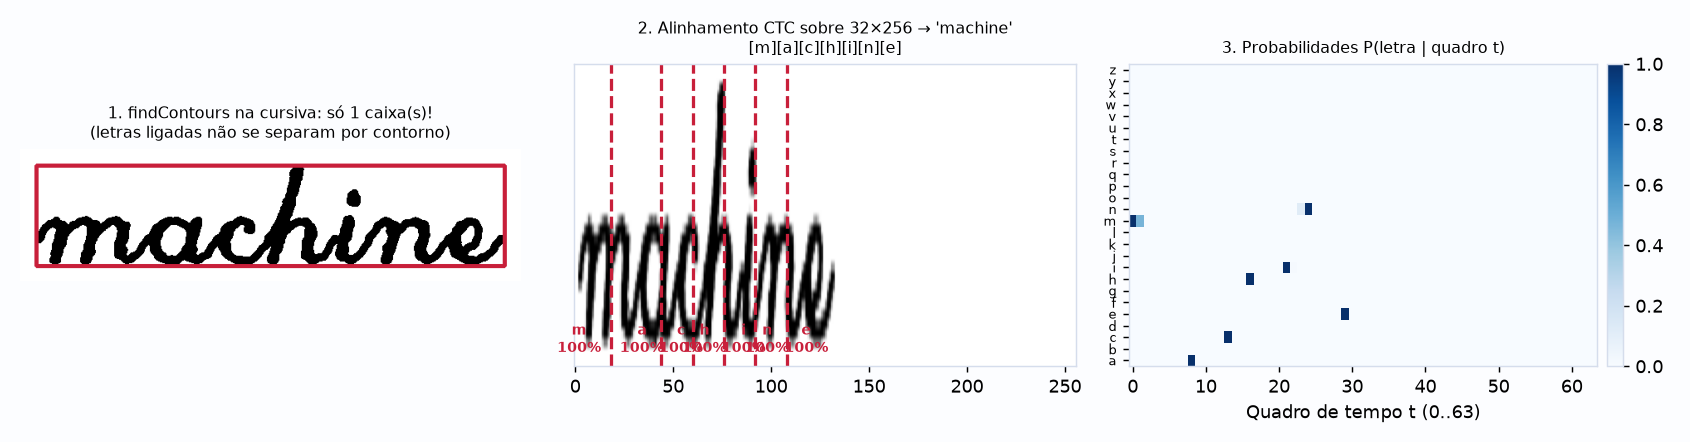

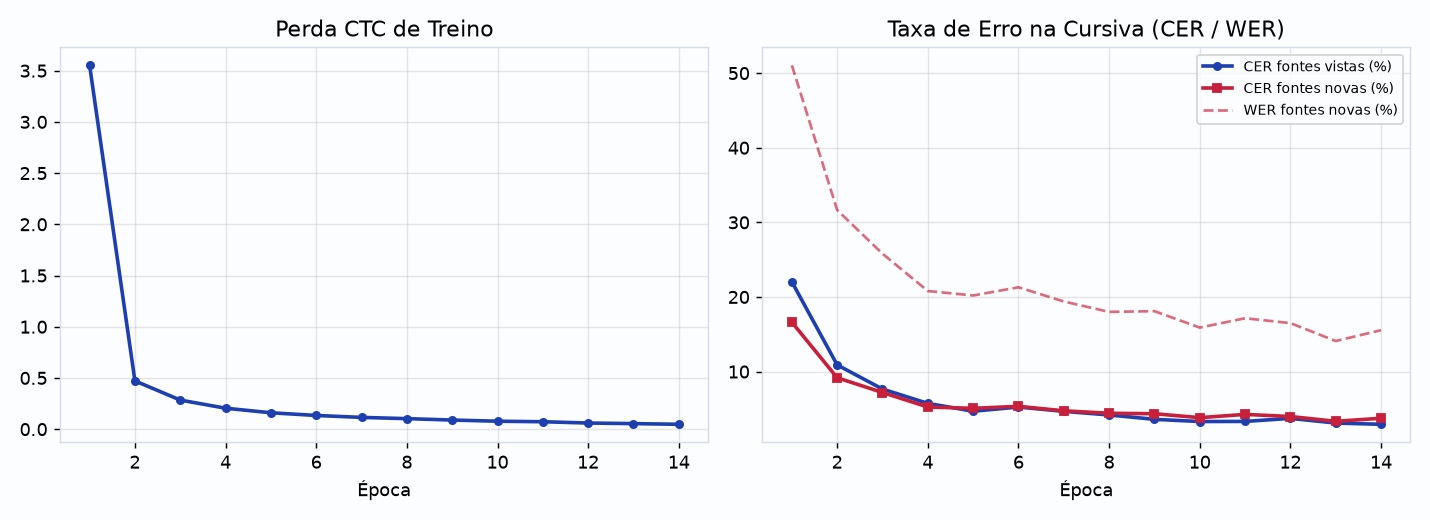

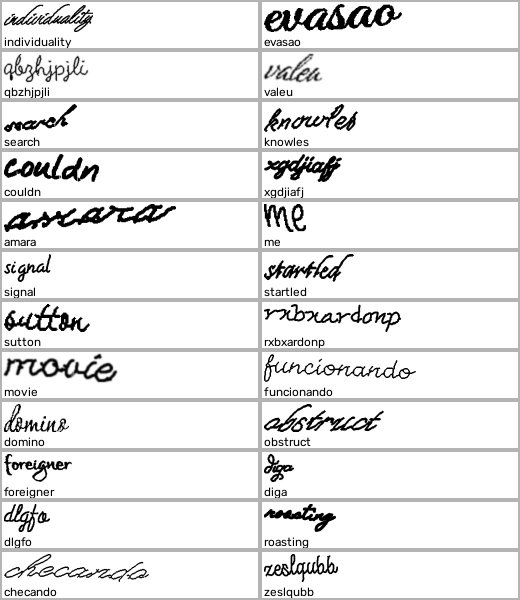

In [4]:
# Demonstração: OpenCV findContours vs Alinhamento CRNN+CTC na mesma palavra cursiva ('machine')
import onnxruntime as ort
import app_pipeline as ap
from eval_hershey import hershey_strokes

sess_crnn = ort.InferenceSession('../space/models/cursive_crnn.onnx', providers=['CPUExecutionProvider'])
strokes = hershey_strokes('machine', 'scriptc', __import__('random').Random(7))
gray = ap.render_strokes(strokes, ap.CURSIVE_LW)
thresh = ap.binarize(gray)
boxes, _ = ap.find_boxes(thresh)
groups = ap.group_letters(ap.drop_noise(boxes))

x_word = ap.cursive_from_gray(gray)
probs = sess_crnn.run(None, {'image': x_word[None, None]})[0][0]  # (64, 27)
pred, spans = ctc_greedy(probs)
print(f'Caixas encontradas por findContours na palavra cursiva: {len(groups)}')
print('Resultado CRNN+CTC:', ''.join(f'[{s[0]}]' for s in spans), '->', pred)
for ch, t0, t1, p in spans:
    print(f'  letra [{ch}] | quadros t={t0:02d}..{t1:02d} (x={t0*4:3d}..{(t1+1)*4:3d} px) | prob={p*100:5.1f}%')

## 4. Segmentação com OpenCV no Modo Letra de Forma

No modo **Letra de forma**, o aplicativo executa no navegador (via `OpenCV.js` em `space/js/preprocess.js`) exatamente a sequência de operações descrita na Seção 4 do enunciado:
1. `cv.cvtColor(src, gray, cv.COLOR_RGBA2GRAY)`
2. `cv.GaussianBlur(gray, blur, new cv.Size(5, 5), 0)`
3. `cv.threshold(blur, thresh, 0, 255, cv.THRESH_BINARY_INV + cv.THRESH_OTSU)`
4. `cv.findContours(thresh, contours, hierarchy, cv.RETR_EXTERNAL, cv.CHAIN_APPROX_SIMPLE)` + `cv.boundingRect(contour)`
5. Agrupamento de componentes verticalmente alinhados (como o pingo de `i` e `j`), ordenação da esquerda para a direita (`key=lambda b: b.x`), normalização de cada letra para `28×28` mantendo a proporção do EMNIST (lado maior = 22 px centralizado) e inferência em lote único no `emnist_cnn.onnx`.

Resultado: [M][a][C][h][1][n][e]
Palavra reconstruída: MaCh1ne


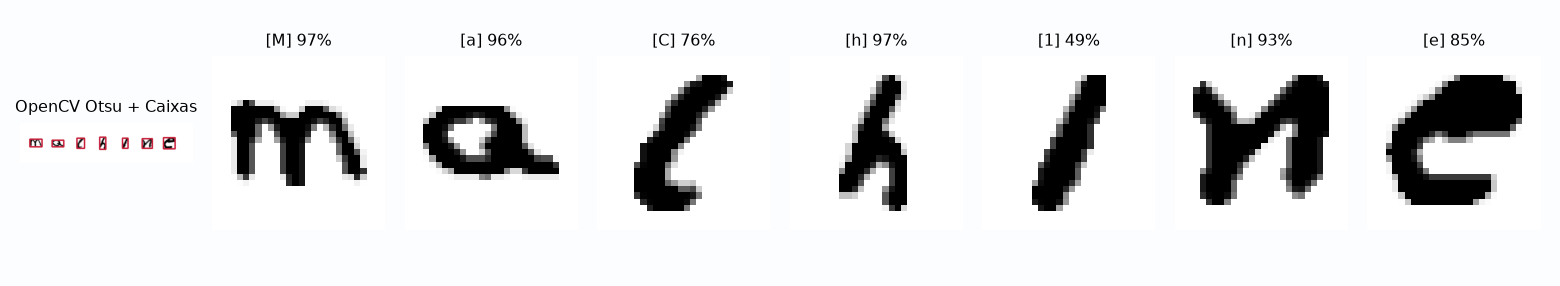

In [5]:
# Demonstração do pipeline OpenCV + CNN EMNIST (modo Letra de forma) na palavra 'Machine'
import cv2
sess_emnist = ort.InferenceSession('../space/models/emnist_cnn.onnx', providers=['CPUExecutionProvider'])
xt_cpu, yt_cpu = x_test[:, 0].cpu().numpy(), y_test.cpu().numpy()
target_word = 'Machine'
img_p = np.full((80, 34 + len(target_word) * 44), 255, np.uint8)
for i, ch in enumerate(target_word):
    cid = EMNIST_CLASSES.index(ch if ch in EMNIST_CLASSES else ch.upper())
    glyph = (xt_cpu[np.where(yt_cpu == cid)[0][0]] * 255).astype(np.uint8)
    img_p[26:54, 18 + i * 44 : 46 + i * 44] = 255 - glyph
thresh_p = ap.binarize(img_p)
boxes_p, contours_p = ap.find_boxes(thresh_p)
sorted_boxes = ap.group_letters(ap.drop_noise(boxes_p))
letters_28 = np.stack([ap.letter_tensor(thresh_p, contours_p, g) for g in sorted_boxes])
preds_p = sess_emnist.run(None, {'image': letters_28[:, None]})[0]
tokens = [EMNIST_CLASSES[k] for k in preds_p.argmax(1)]
print('Resultado:', ''.join(f'[{c}]' for c in tokens))
print('Palavra reconstruída:', ''.join(tokens))

## 5. Exportação para ONNX e Deploy no Hugging Face Spaces (Sem Gradio)

Ambos os modelos foram exportados para **ONNX (opset 17)** com verificação numérica de paridade entre PyTorch e `onnxruntime` (erro absoluto máximo $< 10^{-6}$):
- `space/models/emnist_cnn.onnx` (7,1 MB): entrada dinâmica `[N, 1, 28, 28]` → saída `[N, 47]` com `Softmax` embutido.
- `space/models/cursive_crnn.onnx` (8,1 MB): entrada `[1, 1, 32, 256]` → saída `[1, 64, 27]` com `Softmax` por quadro temporal.

### Arquitetura da Aplicação Web (`space/`)
- **`sdk: static` no Hugging Face Spaces:** sem backend Python, sem Gradio e sem Gradio-Lite.
- **Interface (*O Caderno de Caligrafia*):** folha pautada com linhas-guia em canvas separado (para não interferir na binarização de Otsu), suporte a mouse, toque e caneta com pressão (*Pointer Events*), marcas de segmentação desenhadas sobre a palavra em vermelho-correção, chips individuais por letra com barra de confiança e alternativas *top-3*, correção opcional por dicionário (*beam search* CTC em uma *Trie* de 52 mil palavras PT+EN) e tira visual com os 4 estágios do pipeline.

In [6]:
# Verificação de paridade PyTorch x ONNX Runtime
from export_onnx import export_emnist, export_crnn
err_emnist = export_emnist(Path('../artifacts/emnist_final.pt'))
err_crnn = export_crnn(Path('../artifacts/crnn_best.pt'))
assert err_emnist < 1e-4 and err_crnn < 1e-4, 'Erro de paridade acima do limite!'

EMNIST -> emnist_cnn.onnx (7.1 MB)  max|Δ| = 1.19e-07
CRNN   -> cursive_crnn.onnx (8.1 MB)  max|Δ| = 5.96e-07
